# NOVA-Net — Phase 1: First Dataset Analysis (US only)
**AID 427 · Open Food Facts (Hugging Face Parquet export) → predicting `nova_group`**

This notebook:
1. Downloads the official Parquet export from Hugging Face (`openfoodfacts/product-database`, file `food.parquet`) — **no CSV**.
2. Queries it with **DuckDB** and keeps **United States** products only.
3. Flattens the nested columns (nutrients, names, ingredient text).
4. Runs the exploratory analysis promised in Section E of the proposal: label coverage, class imbalance, missingness (incl. *why* products are unlabeled), impossible values, correlations, text noise, high-cardinality categoricals, sparsity / dimensionality, class separation.
5. Cleans impossible nutrient values (proposal step 2) and saves the cleaned US Parquet files for the next phases.
6. Ends with a table comparing each claim in the proposal with what the data actually shows (Section 16).

**Runtime tip:** use a standard CPU runtime (High-RAM if available). The download is a few GB; everything after that is fast because DuckDB only reads the columns it needs.

## 0. Setup

In [1]:
!pip -q install -U "duckdb>=1.3" "huggingface_hub>=0.25,<2.0"   # <2.0 keeps Colab's preinstalled `datasets` happy

In [2]:
# ======================== CONFIG ========================
HF_REPO        = "openfoodfacts/product-database"
US_TAG         = "en:united-states"   # value used in the `countries_tags` column
STRICT_US_ONLY = False   # False: any product sold in the US (may also be sold elsewhere)
                         # True : products whose countries_tags is ONLY the US
LOCAL_PARQUET  = None    # path to an already-downloaded food.parquet (skips the download)
OUT_DIR        = "/content/nova_outputs"
SAVE_TO_DRIVE  = False   # True -> mount Google Drive and save outputs to DRIVE_DIR
DRIVE_DIR      = "/content/drive/MyDrive/AID427_NOVA_Net"
DUCK_MEM       = "8GB"   # DuckDB memory limit (Colab free has ~12 GB RAM)
TOP_NUTRIENTS  = 20      # how many of the most frequent nutrients to flatten
SEED           = 42

import os, re, json, time, warnings
from collections import Counter
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60, "display.width", 200, "display.float_format", lambda v: f"{v:,.3f}")

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = DRIVE_DIR
os.makedirs(OUT_DIR, exist_ok=True)

SUMMARY = {}   # key numbers collected along the way; printed and saved at the end

## 1. Download the Parquet file from Hugging Face

In [3]:
from huggingface_hub import HfApi, hf_hub_download

if LOCAL_PARQUET and os.path.exists(LOCAL_PARQUET):
    PARQUET = LOCAL_PARQUET
else:
    files = HfApi().list_repo_files(HF_REPO, repo_type="dataset")
    cands = [f for f in files if f.endswith("food.parquet")]
    print("Parquet files in repo:", [f for f in files if f.endswith(".parquet")])
    assert cands, "food.parquet not found in the repo - check the file list printed above"
    HF_FILE = "food.parquet" if "food.parquet" in cands else cands[0]
    t0 = time.time()
    PARQUET = hf_hub_download(repo_id=HF_REPO, filename=HF_FILE, repo_type="dataset")
    print(f"Downloaded in {time.time()-t0:.0f}s")

print("Path:", PARQUET)
print(f"Size: {os.path.getsize(PARQUET)/1e9:.2f} GB")

Parquet files in repo: ['beauty.parquet', 'food.parquet', 'petfood.parquet']


food.parquet: reconstructing file:   0%|          |  0.00B / 7.72GB            

food.parquet: downloading bytes:           |  0.00B            

Downloaded in 83s
Path: /root/.cache/huggingface/hub/datasets--openfoodfacts--product-database/snapshots/e49264ae39d1fb35f7abbc4915dbe715af06345b/food.parquet
Size: 7.72 GB


## 2. Open with DuckDB and inspect the schema

In [4]:
con = duckdb.connect()
con.execute(f"SET memory_limit='{DUCK_MEM}'")
os.makedirs("/tmp/duck_tmp", exist_ok=True)
con.execute("SET temp_directory='/tmp/duck_tmp'")
con.execute(f"CREATE OR REPLACE VIEW food AS SELECT * FROM read_parquet('{PARQUET}')")

schema = con.execute("DESCRIBE food").df()[["column_name", "column_type"]]
COLTYPE = dict(zip(schema.column_name, schema.column_type))
def has(c): return c in COLTYPE

print(f"{len(schema)} columns")
with pd.option_context("display.max_rows", 300, "display.max_colwidth", 110):
    display(schema)

111 columns


,column_name,column_type
0,additives_n,INTEGER
1,additives_tags,VARCHAR[]
2,allergens_tags,VARCHAR[]
3,brands_tags,VARCHAR[]
4,brands,VARCHAR
5,categories,VARCHAR
6,categories_tags,VARCHAR[]
7,categories_properties,"STRUCT(ciqual_food_code INTEGER, agribalyse_food_code INTEGER, agribalyse_proxy_food_code INTEGER)"
8,checkers_tags,VARCHAR[]
9,ciqual_food_name_tags,VARCHAR[]


### 2.1 Whole database: how many products carry a NOVA label?

In [5]:
tot, lab = con.execute("SELECT count(*), count(nova_group) FROM food").fetchone()
print(f"All products      : {tot:,}")
print(f"With nova_group   : {lab:,}  ({lab/tot:.1%})")
SUMMARY.update(all_products=tot, all_labeled=lab)

top_countries = con.execute("""
    SELECT c AS country, count(*) AS n_products, count(nova_group) AS n_labeled
    FROM (SELECT unnest(countries_tags) AS c, nova_group FROM food)
    GROUP BY c ORDER BY n_labeled DESC LIMIT 10
""").df()
display(top_countries)

All products      : 4,807,583
With nova_group   : 1,120,043  (23.3%)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,country,n_products,n_labeled
0,en:united-states,993157,388530
1,en:france,1249972,308753
2,en:germany,426042,107013
3,en:united-kingdom,192372,52449
4,en:spain,354207,48617
5,en:italy,265698,34810
6,en:switzerland,104025,29455
7,en:netherlands,113486,29199
8,en:belgium,101394,26028
9,en:world,70855,25308


## 3. Restrict to the United States
`countries_tags` is a list such as `['en:united-states', 'en:canada']`. By default we keep every product whose list **contains** `en:united-states`.
Set `STRICT_US_ONLY = True` in the config cell if you want products tagged with the US **only**.

In [6]:
US_FILTER = f"list_contains(countries_tags, '{US_TAG}')"
if STRICT_US_ONLY:
    US_FILTER += " AND len(countries_tags) = 1"
print("Filter:", US_FILTER)

us_tot, us_lab = con.execute(f"SELECT count(*), count(nova_group) FROM food WHERE {US_FILTER}").fetchone()
print(f"US products            : {us_tot:,}")
print(f"US with nova_group     : {us_lab:,}  ({us_lab/us_tot:.1%} of US)")
print(f"Proposal said ~394,000 labeled US products -> difference: {us_lab-394_000:+,}")
SUMMARY.update(us_products=us_tot, us_labeled=us_lab, strict_us_only=STRICT_US_ONLY)

Filter: list_contains(countries_tags, 'en:united-states')


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

US products            : 993,157
US with nova_group     : 388,530  (39.1% of US)
Proposal said ~394,000 labeled US products -> difference: -5,470


### 3.1 Which nutrients exist? (US, labeled)
The `nutriments` column is a list of records `{name, value, 100g, serving, unit, ...}`. We use the **`100g`** field.

In [7]:
nut_freq = con.execute(f"""
    SELECT nt.name AS name, count(*) AS n_products
    FROM (SELECT unnest(nutriments) AS nt FROM food WHERE {US_FILTER} AND nova_group IS NOT NULL)
    WHERE nt['100g'] IS NOT NULL
    GROUP BY 1 ORDER BY 2 DESC LIMIT 40
""").df()
nut_freq["share_of_labeled_us"] = nut_freq.n_products / us_lab
display(nut_freq)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,name,n_products,share_of_labeled_us
0,nova-group,372524,0.959
1,energy,364465,0.938
2,fat,364416,0.938
3,energy-kcal,364379,0.938
4,proteins,364218,0.937
5,carbohydrates,363547,0.936
6,sodium,359133,0.924
7,salt,359133,0.924
8,sugars,350896,0.903
9,saturated-fat,327810,0.844


## 4. Flatten into one row per product
- nutrients → one `n_<name>` column per nutrient (per 100 g)
- `product_name` / `ingredients_text` (lists of `{lang, text}`) → one string each (English if available, else the product's main language)
- list columns (categories, labels, additives…) are kept as lists
- `nova_groups`, `nova_groups_tags` are **not** kept (they duplicate the target)
- **Target leakage inside `nutriments`:** the list also contains a `nova-group` entry (the label itself, present for 96% of labeled products — see 3.1) and `nutrition-score-fr/uk` (the Nutri-Score points, computed by Open Food Facts). These are **excluded** from the flattened nutrient columns.

In [8]:
assert has("nutriments") and has("nova_group") and has("countries_tags"), "unexpected schema"

CORE = ["energy-kcal", "fat", "saturated-fat", "carbohydrates", "sugars", "fiber", "proteins", "salt", "sodium"]
# `nutriments` also stores the target (`nova-group`) and computed scores (`nutrition-score-fr`) -> never use them as features
def is_derived(n): return n.startswith(("nova", "nutrition-score", "nutriscore", "nutri-score"))
print("Excluded from nutrients (target / computed score):", [n for n in nut_freq.name if is_derived(n)])
avail = set(nut_freq.name)
top_real = [n for n in nut_freq.name if not is_derived(n)][:TOP_NUTRIENTS]
nut_names = list(dict.fromkeys([n for n in CORE if n in avail] + top_real))
ncol = lambda n: "n_" + re.sub(r"\W", "_", n)
NUT_COLS  = [ncol(n) for n in nut_names]
CORE_COLS = [ncol(n) for n in CORE if n in avail]
assert not any(is_derived(n) for n in nut_names), "target-derived nutrient slipped into the features"
print("Core nutrients used:", CORE_COLS)
print(f"All flattened nutrients ({len(NUT_COLS)}):", NUT_COLS)

def pick_text(col):
    t = COLTYPE.get(col)
    if t is None:
        print(f"  [warn] column '{col}' not in the file -> NULL"); return "CAST(NULL AS VARCHAR)"
    if t.endswith("[]") and "STRUCT" in t and "lang" in t and "text" in t:
        return (f"coalesce(list_filter({col}, lambda x: x.lang = 'en')[1].text, "
                f"list_filter({col}, lambda x: x.lang = 'main')[1].text, {col}[1].text)")
    if t.endswith("[]") and "STRUCT" in t:
        return f"CAST({col}[1] AS VARCHAR)"
    return f"CAST({col} AS VARCHAR)"

def pick_lang(col):
    t = COLTYPE.get(col)
    if t and t.endswith("[]") and "STRUCT" in t and "lang" in t:
        return (f"CASE WHEN len(list_filter({col}, lambda x: x.lang = 'en')) > 0 THEN 'en' "
                f"WHEN len(list_filter({col}, lambda x: x.lang = 'main')) > 0 THEN 'main' "
                f"WHEN len({col}) > 0 THEN 'other' ELSE NULL END")
    return "CAST(NULL AS VARCHAR)"

scalar_cols = [c for c in ["code", "brands", "nutriscore_grade", "nova_group", "ingredients_n",
                           "additives_n", "packaging"] if has(c)]
list_cols   = [c for c in ["categories_tags", "labels_tags", "additives_tags", "allergens_tags",
                           "packaging_tags", "countries_tags"] if has(c)]

sel  = scalar_cols
sel += [f"{pick_text('product_name')} AS product_name_txt",
        f"{pick_text('ingredients_text')} AS ingredients_txt",
        f"{pick_lang('ingredients_text')} AS ingredients_lang"]
sel += list_cols
sel += [f"CAST(list_filter(nutriments, lambda x: x.name = '{n}')[1]['100g'] AS DOUBLE) AS {ncol(n)}" for n in nut_names]

con.execute(f"CREATE OR REPLACE TABLE us_all AS SELECT {', '.join(sel)} FROM food WHERE {US_FILTER}")
print("us_all rows:", con.execute("SELECT count(*) FROM us_all").fetchone()[0])
display(con.execute("DESCRIBE us_all").df()[["column_name", "column_type"]].T)

Excluded from nutrients (target / computed score): ['nova-group', 'nutrition-score-fr']
Core nutrients used: ['n_energy_kcal', 'n_fat', 'n_saturated_fat', 'n_carbohydrates', 'n_sugars', 'n_fiber', 'n_proteins', 'n_salt', 'n_sodium']
All flattened nutrients (20): ['n_energy_kcal', 'n_fat', 'n_saturated_fat', 'n_carbohydrates', 'n_sugars', 'n_fiber', 'n_proteins', 'n_salt', 'n_sodium', 'n_energy', 'n_fruits_vegetables_legumes_estimate_from_ingredients', 'n_fruits_vegetables_nuts_estimate_from_ingredients', 'n_cholesterol', 'n_iron', 'n_calcium', 'n_trans_fat', 'n_vitamin_c', 'n_vitamin_a', 'n_potassium', 'n_added_sugars']


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

us_all rows: 993157


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35
column_name,code,brands,nutriscore_grade,nova_group,ingredients_n,additives_n,packaging,product_name_txt,ingredients_txt,ingredients_lang,categories_tags,labels_tags,additives_tags,allergens_tags,packaging_tags,countries_tags,n_energy_kcal,n_fat,n_saturated_fat,n_carbohydrates,n_sugars,n_fiber,n_proteins,n_salt,n_sodium,n_energy,n_fruits_vegetables_legumes_estimate_from_ingr...,n_fruits_vegetables_nuts_estimate_from_ingredi...,n_cholesterol,n_iron,n_calcium,n_trans_fat,n_vitamin_c,n_vitamin_a,n_potassium,n_added_sugars
column_type,VARCHAR,VARCHAR,VARCHAR,INTEGER,INTEGER,INTEGER,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR[],VARCHAR[],VARCHAR[],VARCHAR[],VARCHAR[],VARCHAR[],DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE


In [9]:
# Materialise the labeled subset in pandas (this is the modelling table)
df = con.execute("SELECT * FROM us_all WHERE nova_group IS NOT NULL").df()
df["nova_group"] = df["nova_group"].astype(int)
print("Labeled US shape:", df.shape, "| memory ~", round(df.memory_usage(deep=True).sum()/1e9, 2), "GB")
print("Distinct nova_group values:", sorted(df.nova_group.unique()))
print("Duplicate barcodes:", df["code"].duplicated().sum() if "code" in df else "n/a")
df.head(3).T

Labeled US shape: (388530, 36) | memory ~ 0.59 GB
Distinct nova_group values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Duplicate barcodes: 0


,0,1,2
code,0000105000011,0000105000042,0000105000196
brands,Lagg's,Lagg's,Lagg's
nutriscore_grade,unknown,unknown,unknown
nova_group,1,1,4
ingredients_n,1,1,3
additives_n,0,0,0
packaging,None,None,None
product_name_txt,Chamomile Herbal Tea,"Lagg's, herbal tea, peppermint",Apple & Cinnamon Tea
ingredients_txt,CHAMOMILE FLOWERS.,Peppermint.,"TEA, CINNAMON & NATURAL APPLE FLAVOR."
ingredients_lang,en,en,en


## 5. Target: class distribution (imbalance)

             count  share
nova_group               
1            38425  0.099
2             9738  0.025
3            66432  0.171
4           273935  0.705
Imbalance ratio (largest / smallest class): 28.1x


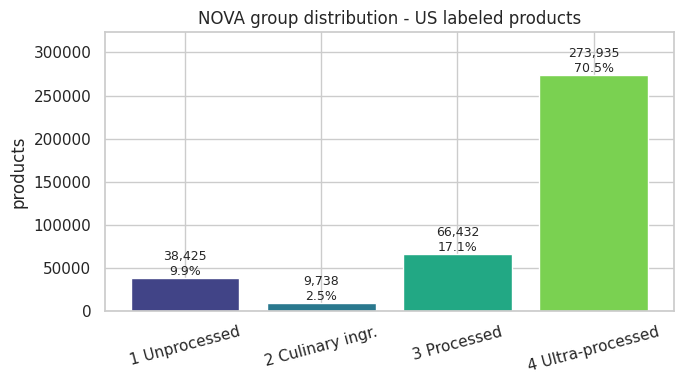

In [10]:
vc = df.nova_group.value_counts().sort_index()
pct = vc / vc.sum()
print(pd.DataFrame({"count": vc, "share": pct}))
print(f"Imbalance ratio (largest / smallest class): {vc.max()/vc.min():.1f}x")
SUMMARY["class_counts"] = {int(k): int(v) for k, v in vc.items()}

names = {1: "1 Unprocessed", 2: "2 Culinary ingr.", 3: "3 Processed", 4: "4 Ultra-processed"}
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([names[i] for i in vc.index], vc.values, color=sns.color_palette("viridis", 4))
for b, v, p in zip(bars, vc.values, pct.values):
    ax.text(b.get_x()+b.get_width()/2, v, f"{v:,}\n{p:.1%}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("products"); ax.set_title("NOVA group distribution - US labeled products")
ax.set_ylim(0, vc.max()*1.18); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 6. Missing values
Missing = `NULL`, empty string, empty list, **or a placeholder** (`unknown`, `not-applicable`, `en:undefined`, …) — e.g. `nutriscore_grade = 'unknown'` or `categories_tags = ['en:undefined']` carry no information. Two views:
1. missingness inside the **labeled** US data (what the model will see)
2. **labeled vs. unlabeled** US products — if they differ a lot, a model trained on labeled rows may not transfer to the unlabeled ones (the actual use case).

Rows:  labeled = 388530 | unlabeled = 604627


,labeled,unlabeled,gap
feature,,,
packaging_tags,0.979,0.992,0.013
packaging,0.979,0.992,0.013
labels_tags,0.829,0.858,0.028
n_added_sugars,0.777,0.746,-0.031
n_potassium,0.649,0.769,0.120
n_vitamin_a,0.465,0.936,0.471
n_vitamin_c,0.450,0.933,0.483
allergens_tags,0.368,0.984,0.616
brands,0.332,0.294,-0.038


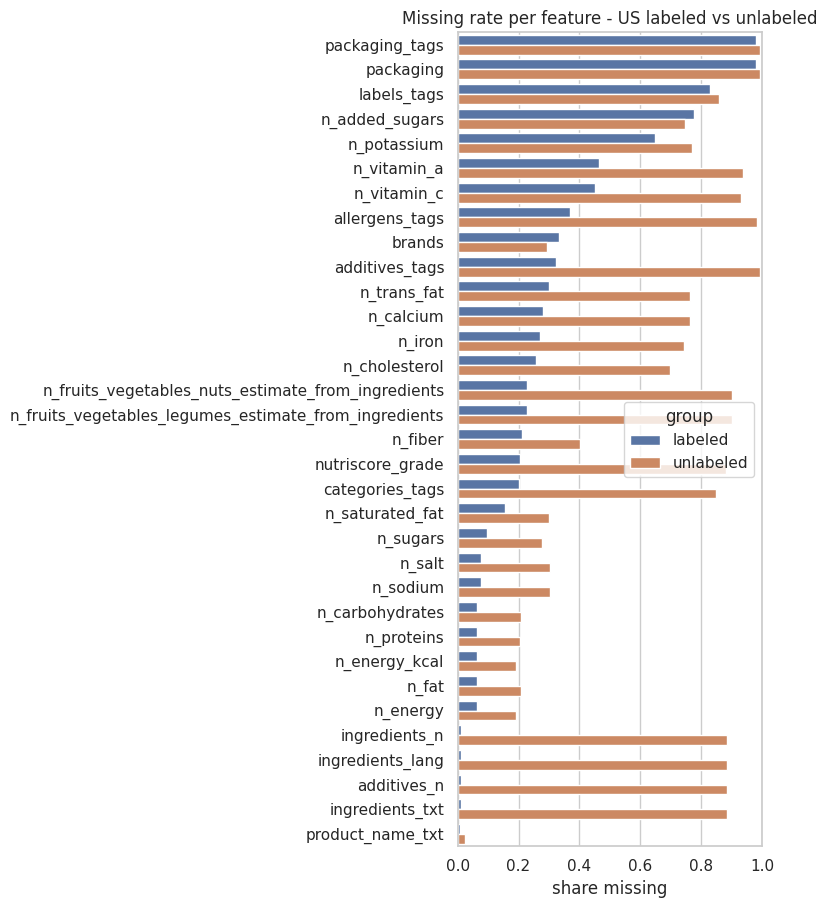

In [11]:
dt = con.execute("DESCRIBE us_all").df().set_index("column_name")["column_type"].to_dict()
PLACEHOLDERS = ("unknown", "not-applicable", "en:undefined", "en:unknown", "en:none")
PH = ", ".join(f"'{p}'" for p in PLACEHOLDERS)
def miss_expr(c):
    t = dt[c]
    if t.endswith("[]"):   return f"({c} IS NULL OR len(list_filter({c}, lambda x: x NOT IN ({PH}))) = 0)"
    if t == "VARCHAR":     return f"({c} IS NULL OR trim({c}) = '' OR lower(trim({c})) IN ({PH}))"
    return f"({c} IS NULL)"

feat_cols = [c for c in dt if c not in ("nova_group", "code", "countries_tags")]
q = ", ".join(f"avg(CAST({miss_expr(c)} AS INTEGER)) AS \"{c}\"" for c in feat_cols)
m = con.execute(f"SELECT (nova_group IS NOT NULL) AS labeled, count(*) AS n, {q} FROM us_all GROUP BY 1").df().set_index("labeled")
print("Rows:  labeled =", int(m.loc[True, "n"]), "| unlabeled =", int(m.loc[False, "n"]))
miss = m.drop(columns="n").T.rename(columns={True: "labeled", False: "unlabeled"})[["labeled", "unlabeled"]]
miss.columns.name = None; miss.index.name = "feature"
miss["gap"] = miss.unlabeled - miss.labeled
miss = miss.sort_values("labeled", ascending=False)
display(miss)

plot = miss.reset_index().melt(id_vars="feature", value_vars=["labeled", "unlabeled"], var_name="group", value_name="missing_rate")
fig, ax = plt.subplots(figsize=(8, max(5, 0.28*len(miss))))
sns.barplot(data=plot, y="feature", x="missing_rate", hue="group", order=miss.index, ax=ax)
ax.set_xlim(0, 1); ax.set_title("Missing rate per feature - US labeled vs unlabeled"); ax.set_xlabel("share missing"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
SUMMARY["missing_rate_labeled"] = miss.labeled.round(4).to_dict()

### 6.1 Why are products unlabeled?
Open Food Facts does not get NOVA from manufacturers: it **computes** it with a rule-based formula over the product's **ingredients and categories** (additive / ingredient "markers" for group 4, culinary-ingredient categories for group 2, etc. — see openfoodfacts.org/nova).
So a missing label should mostly mean missing ingredients. This matters for the proposal's use case ("label the products that have no NOVA group"): a model can only help where some input is available.

In [12]:
has_txt = "(ingredients_txt IS NOT NULL AND trim(ingredients_txt) <> '')"
has_cat = "(categories_tags IS NOT NULL AND len(list_filter(categories_tags, lambda x: x NOT IN ('en:undefined', 'en:unknown'))) > 0)"
has_nut = " OR ".join(f"{c} IS NOT NULL" for c in CORE_COLS)
gap = con.execute(f"""
    SELECT (nova_group IS NOT NULL) AS labeled, {has_txt} AS has_ingredients, {has_cat} AS has_categories,
           ({has_nut}) AS has_nutrition, count(*) AS n
    FROM us_all GROUP BY ALL ORDER BY ALL
""").df()
gap["share_within_group"] = gap.n / gap.groupby("labeled").n.transform("sum")
display(gap)

unl = gap[~gap.labeled]
n_unl = int(unl.n.sum())
n_unl_txt = int(unl[unl.has_ingredients].n.sum())
n_unl_nothing = int(unl[~unl.has_ingredients & ~unl.has_categories & ~unl.has_nutrition].n.sum())
print(f"Unlabeled US products                         : {n_unl:,}")
print(f"  ... WITH ingredient text (text model usable): {n_unl_txt:,}  ({n_unl_txt/n_unl:.1%})")
print(f"  ... with NO ingredients, categories or nutrition (nothing to predict from): {n_unl_nothing:,}  ({n_unl_nothing/n_unl:.1%})")
SUMMARY.update(unlabeled_us=n_unl, unlabeled_with_ingredients=n_unl_txt, unlabeled_no_inputs=n_unl_nothing)

,labeled,has_ingredients,has_categories,has_nutrition,n,share_within_group
0,False,False,False,False,94718,0.157
1,False,False,False,True,394871,0.653
2,False,False,True,False,9298,0.015
3,False,False,True,True,35787,0.059
4,False,True,False,False,5685,0.009
5,False,True,False,True,18164,0.030
6,False,True,True,False,1593,0.003
7,False,True,True,True,44511,0.074
8,True,False,True,False,859,0.002
9,True,False,True,True,3280,0.008


Unlabeled US products                         : 604,627
  ... WITH ingredient text (text model usable): 69,953  (11.6%)
  ... with NO ingredients, categories or nutrition (nothing to predict from): 94,718  (15.7%)


## 7. Nutrition values: coverage, ranges, impossible values

In [13]:
nut = df[NUT_COLS]
desc = nut.describe(percentiles=[.01, .5, .99]).T
desc["missing_%"] = nut.isna().mean() * 100
display(desc[["count", "missing_%", "min", "1%", "50%", "99%", "max"]])

core = df[CORE_COLS]
n_core = core.notna().sum(axis=1)
print("\nProducts by number of core nutrients present:")
print(n_core.value_counts().sort_index().to_frame("products").assign(share=lambda d: d.products/len(df)))
print("No nutrition data at all (core):", f"{(n_core==0).mean():.1%}")

,count,missing_%,min,1%,50%,99%,max
n_energy_kcal,"364,379.000",6.216,0.000,0.000,283.000,"1,910.000","286,500.000"
n_fat,"364,416.000",6.206,0.000,0.000,5.560,115.000,"1,000,000.000"
n_saturated_fat,"327,810.000",15.628,0.000,0.000,1.790,50.000,"10,000.000"
n_carbohydrates,"363,547.000",6.430,-1.000,0.000,25.000,234.000,"7,000.000"
n_sugars,"350,896.000",9.686,0.000,0.000,6.470,133.000,"10,000,000,000.000"
n_fiber,"306,480.000",21.118,-44.700,0.000,1.400,28.571,"10,000,000.000"
n_proteins,"364,218.000",6.257,-12.600,0.000,4.600,66.300,"1,000,000,000.000"
n_salt,"359,133.000",7.566,0.000,0.000,0.508,20.617,"250,000.000"
n_sodium,"359,133.000",7.566,0.000,0.000,0.205,8.143,"100,000.000"
n_energy,"364,465.000",6.194,-700.000,0.000,"1,195.000","8,010.000","196,648.000"



Products by number of core nutrients present:
   products  share
0     22188  0.057
1       302  0.001
2       865  0.002
3       240  0.001
4       977  0.003
5      1415  0.004
6      8290  0.021
7     32387  0.083
8     26966  0.069
9    294900  0.759
No nutrition data at all (core): 5.7%


In [14]:
# Physically impossible / inconsistent values (per 100 g)
checks = {}
for c in CORE_COLS:
    checks[f"{c} < 0"] = (df[c] < 0).sum()
for c in [x for x in CORE_COLS if x != "n_energy_kcal"]:
    checks[f"{c} > 100 g"] = (df[c] > 100).sum()
if "n_energy_kcal" in df: checks["energy-kcal > 900"] = (df["n_energy_kcal"] > 900).sum()
if {"n_sugars", "n_carbohydrates"} <= set(df): checks["sugars > carbs + 0.5"] = (df.n_sugars > df.n_carbohydrates + 0.5).sum()
if {"n_saturated_fat", "n_fat"} <= set(df):    checks["sat. fat > fat + 0.5"] = (df.n_saturated_fat > df.n_fat + 0.5).sum()
if {"n_fat", "n_carbohydrates", "n_proteins"} <= set(df):
    checks["fat+carbs+protein > 105 g"] = ((df.n_fat + df.n_carbohydrates + df.n_proteins) > 105).sum()
chk = pd.Series(checks, name="rows").to_frame().assign(share=lambda d: d.rows/len(df))
display(chk[chk.rows > 0].sort_values("rows", ascending=False))
SUMMARY["impossible_value_checks"] = {k: int(v) for k, v in checks.items() if v > 0}

,rows,share
fat+carbs+protein > 105 g,15441,0.040
energy-kcal > 900,11277,0.029
n_carbohydrates > 100 g,10452,0.027
n_sugars > 100 g,5103,0.013
n_fat > 100 g,4669,0.012
n_proteins > 100 g,907,0.002
n_saturated_fat > 100 g,643,0.002
sugars > carbs + 0.5,603,0.002
sat. fat > fat + 0.5,410,0.001
n_salt > 100 g,357,0.001


### 7.1 Nutrients by NOVA group

nova_group,1 Unprocessed,2 Culinary ingr.,3 Processed,4 Ultra-processed
n_energy_kcal,80.000,643.000,250.000,292.000
n_fat,0.000,64.290,7.140,7.040
n_saturated_fat,0.000,10.000,1.400,2.500
n_carbohydrates,12.500,0.000,14.290,32.350
n_sugars,3.570,0.000,3.230,10.000
n_fiber,2.400,0.000,1.800,1.200
n_proteins,3.330,0.000,6.670,4.650
n_salt,0.000,0.000,0.820,0.630
n_sodium,0.000,0.000,0.330,0.260


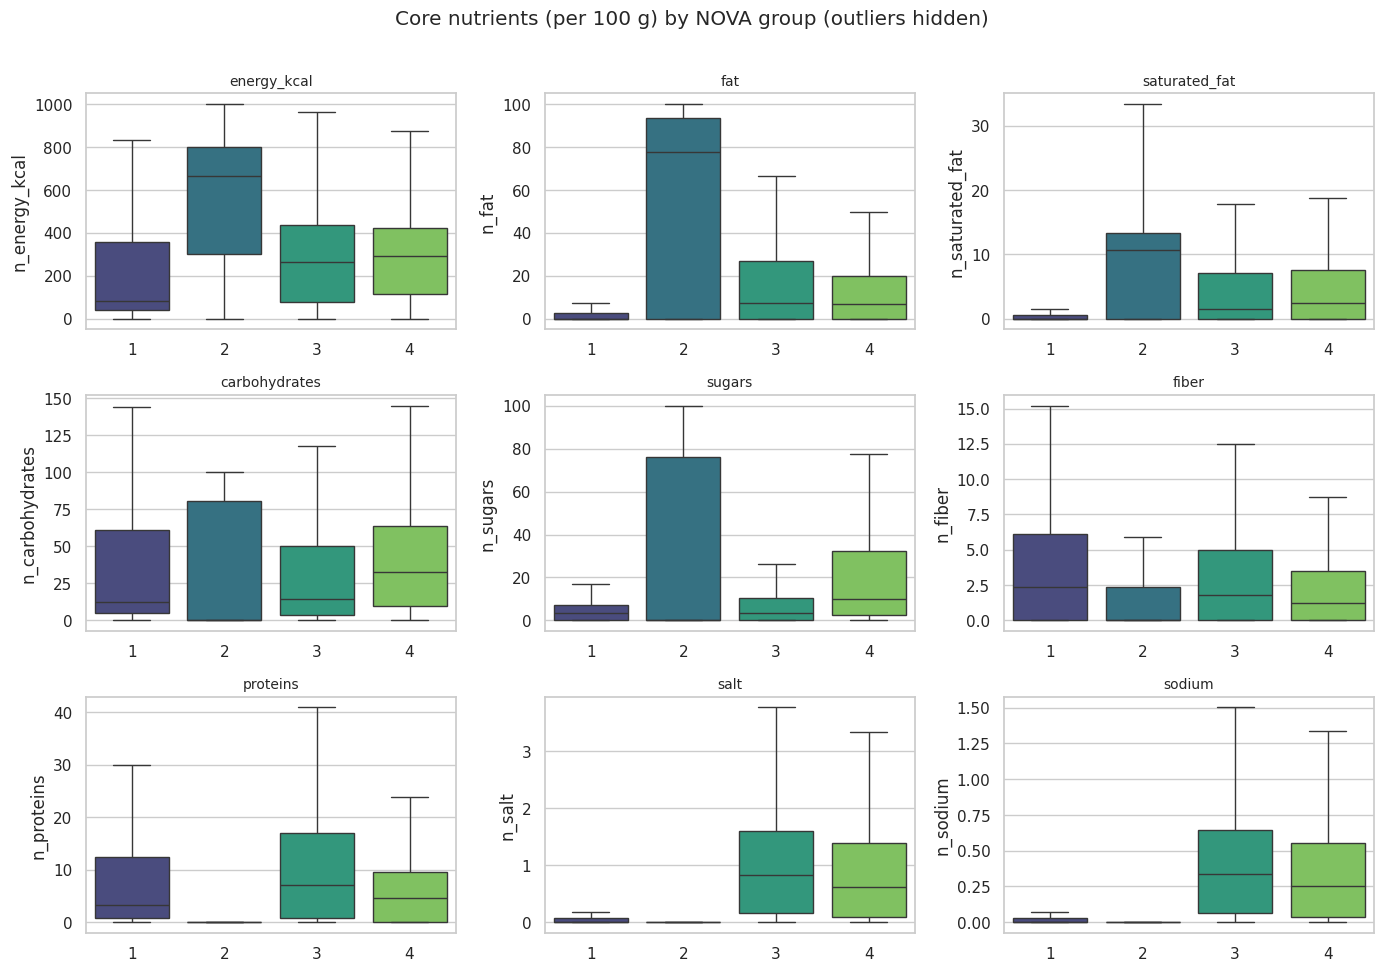

In [15]:
display(df.groupby("nova_group")[CORE_COLS].median().T.rename(columns=names).round(2))

samp = df.sample(min(60_000, len(df)), random_state=SEED)
ncols = 3; nrows = int(np.ceil(len(CORE_COLS)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2*nrows))
for ax, c in zip(np.ravel(axes), CORE_COLS):
    d = samp[(samp[c] >= 0)]
    sns.boxplot(data=d, x="nova_group", y=c, showfliers=False, palette="viridis", ax=ax)
    ax.set_title(c.replace("n_", ""), fontsize=10); ax.set_xlabel("")
for ax in np.ravel(axes)[len(CORE_COLS):]: ax.axis("off")
fig.suptitle("Core nutrients (per 100 g) by NOVA group (outliers hidden)", y=1.01); plt.tight_layout(); plt.show()

## 8. Count features: ingredients and additives

ingredients_n             additives_n           
                    mean median  max        mean median max
nova_group                                                 
1                  3.200  2.000   85       0.090  0.000  16
2                  2.130  1.000   45       0.040  0.000   5
3                  8.980  7.000   97       0.360  0.000  10
4                 22.830 18.000  443       3.640  3.000  39

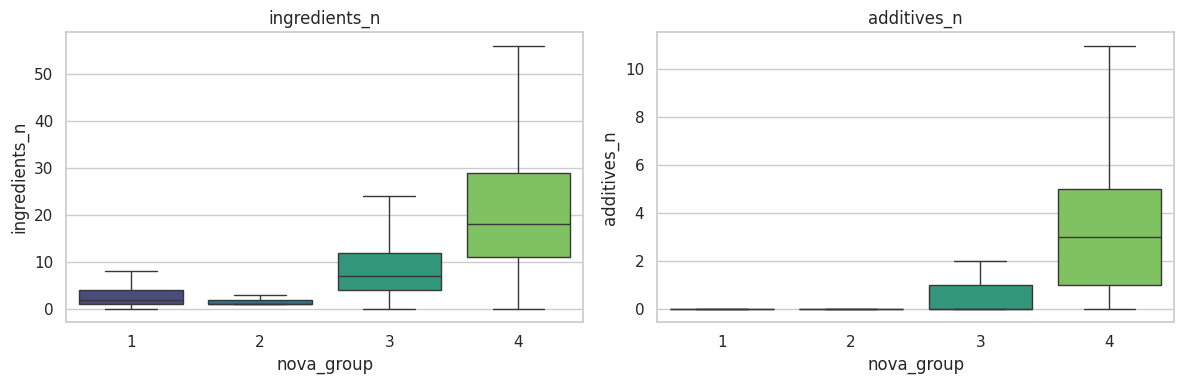


Share of each NOVA group by number of additives (5 = 5 or more):


additives_n,0,1,2,3,4,5,missing
nova_group,,,,,,,
1,0.908,0.068,0.007,0.001,0.000,0.000,0.016
2,0.620,0.016,0.001,0.001,0.000,0.000,0.362
3,0.731,0.202,0.051,0.012,0.003,0.001,0.000
4,0.115,0.196,0.160,0.126,0.102,0.301,0.000


In [16]:
cf = [c for c in ["ingredients_n", "additives_n"] if c in df]
display(df.groupby("nova_group")[cf].agg(["mean", "median", "max"]).round(2))

fig, axes = plt.subplots(1, len(cf), figsize=(6*len(cf), 4))
for ax, c in zip(np.atleast_1d(axes), cf):
    sns.boxplot(data=df, x="nova_group", y=c, showfliers=False, palette="viridis", ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

if "additives_n" in df:
    ct = pd.crosstab(df.nova_group, df.additives_n.fillna(-1).clip(upper=5).astype(int).replace({-1: "missing"}), normalize="index")
    print("\nShare of each NOVA group by number of additives (5 = 5 or more):")
    display(ct)

## 9. Correlated features

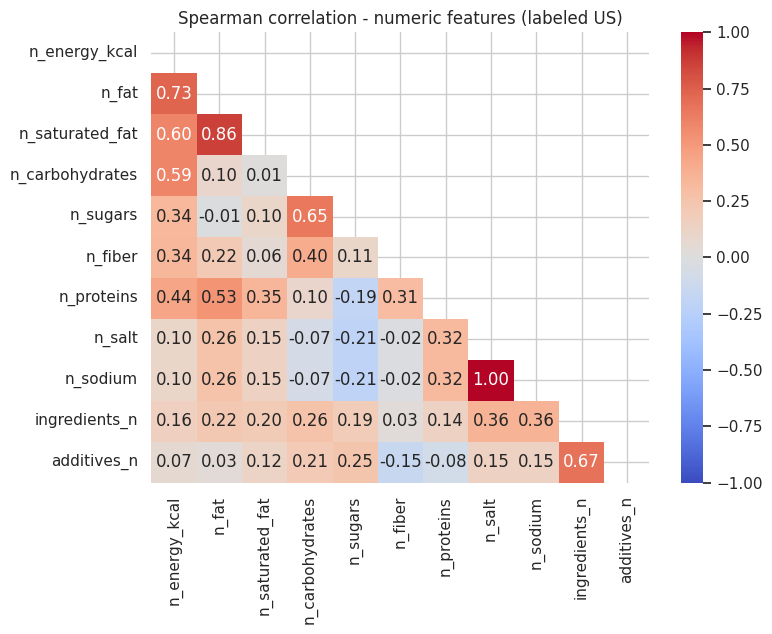

Strongly correlated pairs (|rho| >= 0.7):


,a,b,rho
35,n_sodium,n_salt,0.995
2,n_saturated_fat,n_fat,0.864
0,n_fat,n_energy_kcal,0.730


Spearman correlation with nova_group:


,rho
additives_n,0.645
ingredients_n,0.613
n_sugars,0.248
n_salt,0.228
n_sodium,0.228
n_carbohydrates,0.175
n_saturated_fat,0.161
n_fiber,-0.118
n_fat,0.078
n_energy_kcal,0.078


In [17]:
num_cols = [c for c in CORE_COLS + cf if c in df]
corr = df[num_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation - numeric features (labeled US)"); plt.tight_layout(); plt.show()

pairs = (corr.where(~mask).stack().rename("rho").reset_index().rename(columns={"level_0": "a", "level_1": "b"}))
pairs = pairs[pairs.rho.abs() >= 0.7].sort_values("rho", key=abs, ascending=False)
print("Strongly correlated pairs (|rho| >= 0.7):"); display(pairs)

# Correlation of each numeric feature with the target (ordinal NOVA, Spearman)
tgt = df[num_cols].apply(lambda s: s.corr(df.nova_group, method="spearman")).sort_values(key=abs, ascending=False)
print("Spearman correlation with nova_group:"); display(tgt.to_frame("rho"))

## 10. Ingredient text: coverage, noise, language

Labeled US products WITH ingredient text: 98.9%


,share_with_text
nova_group,
1,0.984
2,0.638
3,1.000
4,1.000



Language slot of the text we kept (en = English entry exists, main = product's original language):


ingredients_lang,en,main,none
nova_group,,,
1,0.978,0.006,0.016
2,0.634,0.004,0.362
3,0.995,0.005,0.000
4,0.994,0.006,0.000


,chars,words,commas,non_ascii_share,upper_share
nova_group,,,,,
1,35.000,4.000,1.000,0.000,0.050
2,23.000,4.000,0.000,0.000,0.053
3,101.000,14.000,5.000,0.000,0.017
4,283.000,36.000,14.000,0.000,0.006


Texts with >5% non-ASCII chars (accents / other scripts): 0.1%
Texts mostly UPPERCASE (>70% of letters): 14.1%
Very short texts (<15 chars): 2.9%
Exact duplicate ingredient texts: 18.0%


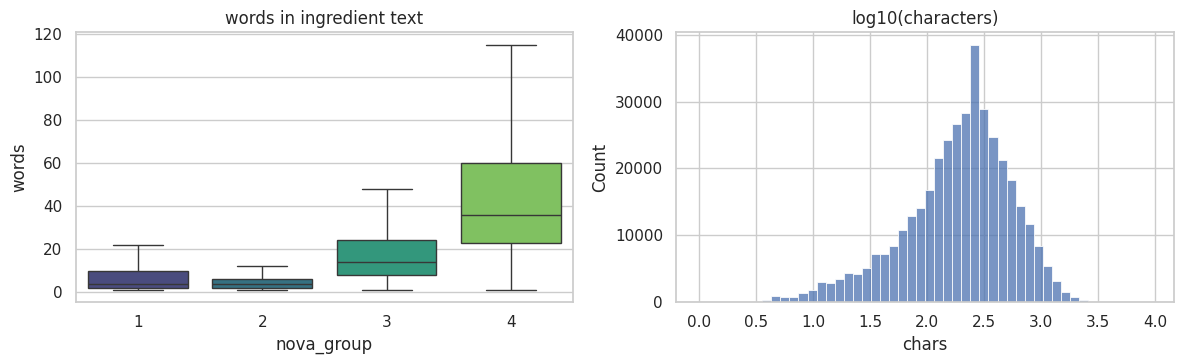

In [18]:
ing = df["ingredients_txt"].fillna("")
has_ing = ing.str.strip().ne("")
print(f"Labeled US products WITH ingredient text: {has_ing.mean():.1%}")
display(has_ing.groupby(df.nova_group).mean().rename("share_with_text").to_frame())

if df["ingredients_lang"].notna().any():
    print("\nLanguage slot of the text we kept (en = English entry exists, main = product's original language):")
    display(pd.crosstab(df.nova_group, df.ingredients_lang.fillna("none"), normalize="index"))

t = ing[has_ing]
stats = pd.DataFrame({
    "chars":  t.str.len(),
    "words":  t.str.split().str.len(),
    "commas": t.str.count(","),
    "non_ascii_share": t.apply(lambda s: sum(ord(ch) > 127 for ch in s) / max(len(s), 1)),
    "upper_share": t.apply(lambda s: (sum(ch.isupper() for ch in s) / max(sum(ch.isalpha() for ch in s), 1))),
})
stats["nova_group"] = df.loc[has_ing, "nova_group"].values
display(stats.groupby("nova_group").median().round(3))
print("Texts with >5% non-ASCII chars (accents / other scripts):", f"{(stats.non_ascii_share > .05).mean():.1%}")
print("Texts mostly UPPERCASE (>70% of letters):", f"{(stats.upper_share > .70).mean():.1%}")
print("Very short texts (<15 chars):", f"{(stats.chars < 15).mean():.1%}")
print("Exact duplicate ingredient texts:", f"{t.duplicated().mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(data=stats, x="nova_group", y="words", showfliers=False, palette="viridis", ax=ax[0]); ax[0].set_title("words in ingredient text")
sns.histplot(np.log10(stats.chars.clip(lower=1)), bins=50, ax=ax[1]); ax[1].set_title("log10(characters)")
plt.tight_layout(); plt.show()
SUMMARY["share_with_ingredient_text"] = float(has_ing.mean())

### 10.1 Most over-represented words per class

In [19]:
from sklearn.feature_extraction.text import CountVectorizer
idx = has_ing[has_ing].sample(min(100_000, int(has_ing.sum())), random_state=SEED).index
cv = CountVectorizer(stop_words="english", min_df=30, binary=True, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
Xw = cv.fit_transform(ing.loc[idx].str.lower())
vocab = np.array(cv.get_feature_names_out())
y = df.loc[idx, "nova_group"].values
overall = np.asarray(Xw.mean(0)).ravel()
rows = {}
for k in sorted(set(y)):
    fr = np.asarray(Xw[y == k].mean(0)).ravel()
    top = np.argsort(-(fr - overall))[:12]
    rows[names[k]] = [f"{vocab[i]} ({fr[i]:.0%})" for i in top]
display(pd.DataFrame(rows))

,1 Unprocessed,2 Culinary ingr.,3 Processed,4 Ultra-processed
0,organic (21%),olive (21%),salt (82%),natural (61%)
1,semolina (8%),virgin (19%),sea (25%),sugar (64%)
2,durum (8%),extra (17%),organic (17%),flavor (43%)
3,ferrous (6%),honey (17%),olive (9%),corn (44%)
4,apples (3%),organic (22%),tomatoes (8%),acid (55%)
5,broccoli (3%),oil (49%),garlic (22%),sodium (35%)
6,beans (5%),roasted (8%),pepper (13%),syrup (33%)
7,peas (2%),pure (6%),black (9%),gum (29%)
8,apple (6%),refined (4%),virgin (5%),starch (31%)
9,pineapple (3%),peanuts (7%),beans (6%),soy (29%)


## 11. High-cardinality categoricals

In [20]:
def _len(v): return len(v) if hasattr(v, "__len__") and not isinstance(v, str) else 0

def tag_stats(series, label, topn=12):
    cnt, empty = Counter(), 0
    for v in series:
        if _len(v) == 0: empty += 1; continue
        cnt.update(set(v))
    tot = sum(cnt.values()); common = cnt.most_common()
    out = {"feature": label, "distinct": len(cnt), "empty_rows_%": 100*empty/len(series)}
    for k in (10, 100, 1000):
        out[f"top{k}_cover_%"] = 100*sum(c for _, c in common[:k])/max(tot, 1)
    return out, common[:topn]

res, tops = [], {}
for c in [x for x in ["categories_tags", "labels_tags", "additives_tags", "allergens_tags", "packaging_tags"] if x in df]:
    r, tp = tag_stats(df[c], c); res.append(r); tops[c] = tp
brand_lists = df["brands"].fillna("").str.lower().str.split(",").apply(lambda L: [b.strip() for b in L if b.strip()]) if "brands" in df else None
if brand_lists is not None:
    r, tp = tag_stats(brand_lists, "brands"); res.append(r); tops["brands"] = tp
display(pd.DataFrame(res).set_index("feature"))
for k, v in tops.items():
    print(f"\nTop values - {k}:", ", ".join(f"{a} ({b:,})" for a, b in v[:8]))
SUMMARY["cardinality"] = {r["feature"]: int(r["distinct"]) for r in res}

,distinct,empty_rows_%,top10_cover_%,top100_cover_%,top1000_cover_%
feature,,,,,
categories_tags,9844,11.484,35.990,83.098,98.020
labels_tags,2474,82.934,78.362,95.071,98.993
additives_tags,515,32.237,37.827,93.073,100.000
allergens_tags,543,36.789,91.358,99.910,100.000
packaging_tags,1208,97.946,46.675,82.592,98.213
brands,41629,33.207,6.705,23.988,54.295



Top values - categories_tags: en:snacks (87,233), en:plant-based-foods-and-beverages (75,945), en:plant-based-foods (64,644), en:sweet-snacks (49,545), en:undefined (33,585), en:beverages (32,030), en:condiments (30,822), en:cereals-and-potatoes (26,914)

Top values - labels_tags: en:organic (21,094), en:no-gluten (19,855), en:no-gmos (18,261), en:non-gmo-project (17,237), en:vegetarian (8,012), en:vegan (7,621), en:kosher (7,255), en:usda-organic (6,545)

Top values - additives_tags: en:e330 (98,361), en:e322 (67,710), en:e322i (67,254), en:e415 (39,223), en:e500 (38,728), en:e500ii (37,717), en:e412 (27,897), en:e129 (27,458)

Top values - allergens_tags: en:milk (123,399), en:soybeans (111,308), en:gluten (95,453), en:eggs (37,685), en:nuts (27,609), en:peanuts (17,723), en:celery (12,508), en:sesame-seeds (10,414)

Top values - packaging_tags: en:plastic (1,990), en:bottle (643), en:bag (549), en:box (488), en:glass (355), en:can (334), en:cardboard (304), en:paper (269)

Top valu

### 11.1 How much does category alone tell us about NOVA?

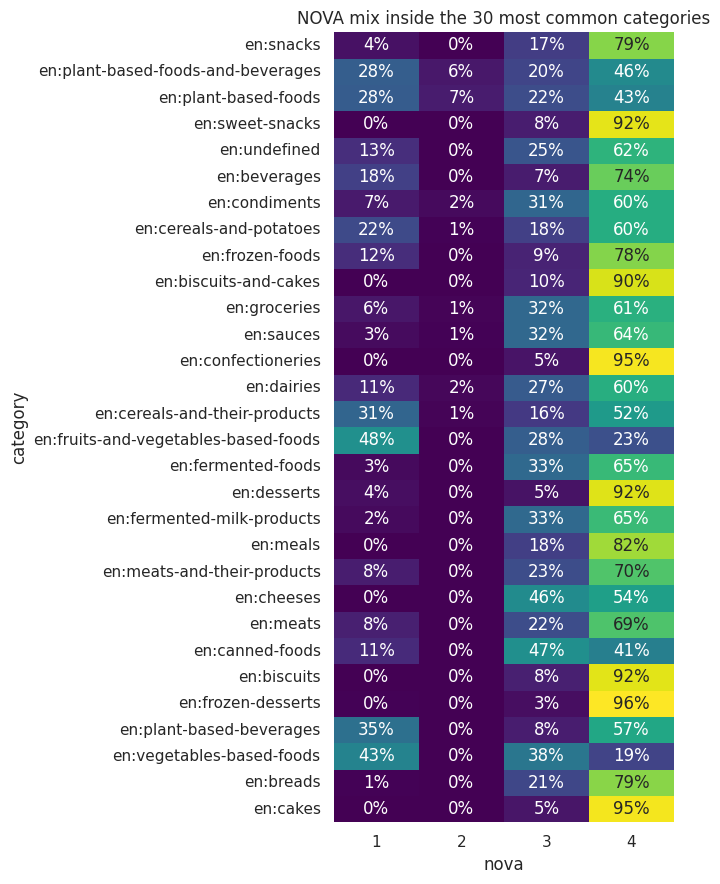

In [21]:
if "categories_tags" in df:
    cnt = Counter(t for v in df.categories_tags if _len(v) for t in set(v))
    topset = {t for t, _ in cnt.most_common(30)}
    rows = [(t, nv) for v, nv in zip(df.categories_tags, df.nova_group) if _len(v) for t in set(v) if t in topset]
    ctab = pd.crosstab(pd.Series([r[0] for r in rows], name="category"), pd.Series([r[1] for r in rows], name="nova"), normalize="index")
    ctab["n"] = pd.Series(cnt)[ctab.index]
    ctab = ctab.sort_values("n", ascending=False)
    fig, ax = plt.subplots(figsize=(7, 9))
    sns.heatmap(ctab.drop(columns="n"), annot=True, fmt=".0%", cmap="viridis", cbar=False, ax=ax)
    ax.set_title("NOVA mix inside the 30 most common categories"); plt.tight_layout(); plt.show()

## 12. High dimensionality & sparsity: TF-IDF + SVD (preview)

TF-IDF matrix: (60000, 35432) | non-zeros/doc: 60.0 | density: 0.1693%
components for 30% variance: >100 (100 comps = 24.5%)
components for 50% variance: >100 (100 comps = 24.5%)
components for 70% variance: >100 (100 comps = 24.5%)


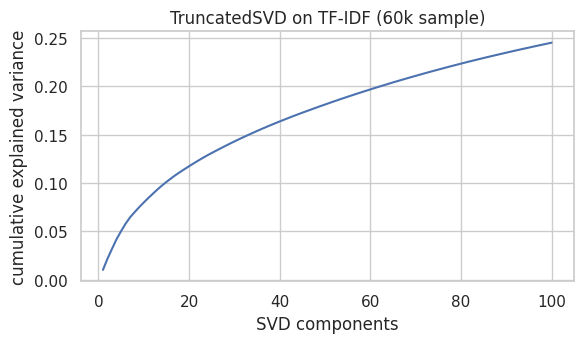

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

idx2 = has_ing[has_ing].sample(min(60_000, int(has_ing.sum())), random_state=SEED).index
tfidf = TfidfVectorizer(min_df=5, ngram_range=(1, 2), sublinear_tf=True, strip_accents="unicode", lowercase=True)
Xt = tfidf.fit_transform(ing.loc[idx2])
print("TF-IDF matrix:", Xt.shape, "| non-zeros/doc:", round(Xt.nnz / Xt.shape[0], 1), "| density:", f"{Xt.nnz/(Xt.shape[0]*Xt.shape[1]):.4%}")

svd = TruncatedSVD(n_components=100, random_state=SEED).fit(Xt)
cum = np.cumsum(svd.explained_variance_ratio_)
for tgt_v in (.3, .5, .7):
    k = int(np.searchsorted(cum, tgt_v)) + 1
    print(f"components for {tgt_v:.0%} variance:", k if cum[-1] >= tgt_v else f">100 (100 comps = {cum[-1]:.1%})")
fig, ax = plt.subplots(figsize=(6, 3.6)); ax.plot(range(1, 101), cum); ax.set_xlabel("SVD components"); ax.set_ylabel("cumulative explained variance")
ax.set_title("TruncatedSVD on TF-IDF (60k sample)"); plt.tight_layout(); plt.show()
SUMMARY["tfidf_dims"] = int(Xt.shape[1]); SUMMARY["svd100_variance"] = float(cum[-1])

### 12.1 Numeric features: PCA preview of class overlap

Explained variance ratio (numeric features): [0.341 0.225 0.181 0.12  0.067 0.038 0.021 0.006 0.002]


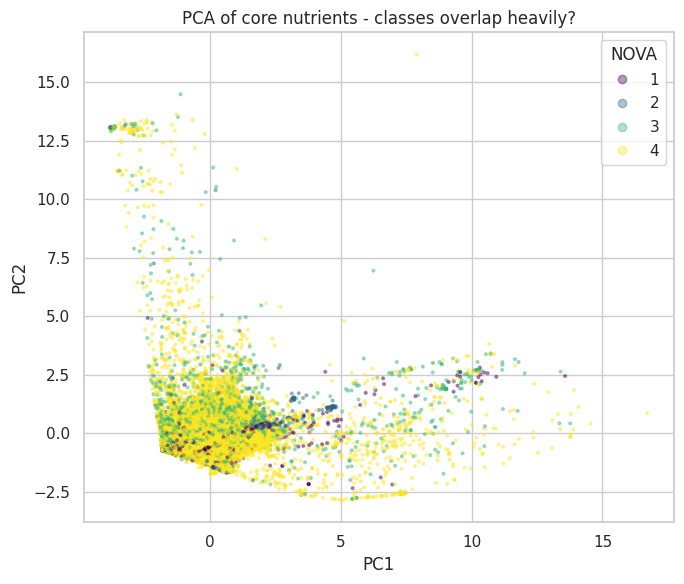

In [23]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

dd = df[df[CORE_COLS].notna().sum(axis=1) >= max(3, len(CORE_COLS)-2)]
dd = dd.sample(min(25_000, len(dd)), random_state=SEED)
Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(dd[CORE_COLS].clip(lower=0, upper=dd[CORE_COLS].quantile(.995), axis=1)))
pca = PCA().fit(Z); P = pca.transform(Z)
print("Explained variance ratio (numeric features):", np.round(pca.explained_variance_ratio_, 3))
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(P[:, 0], P[:, 1], c=dd.nova_group, cmap="viridis", s=4, alpha=.4)
ax.legend(*sc.legend_elements(), title="NOVA", loc="upper right"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("PCA of core nutrients - classes overlap heavily?"); plt.tight_layout(); plt.show()

### 12.2 Class separation: PCA vs LDA, silhouette and mutual information
The proposal (Section E) promises a class-separation analysis. Three quick checks on the same scaled core nutrients:
- **LDA** (supervised) vs **PCA** (unsupervised) 2-D projections,
- **silhouette score** of the NOVA classes in each space (balanced sample; ≈0 or negative = classes overlap),
- **mutual information** between each feature and `nova_group` (how much a single feature tells about the class, nonlinear-aware).

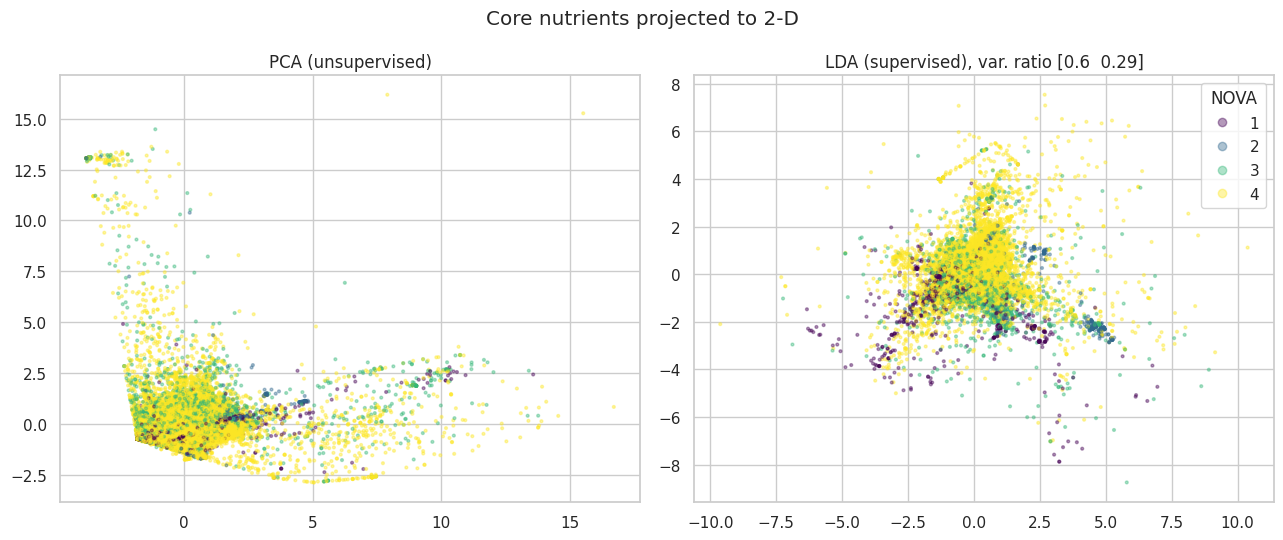

,silhouette (NOVA classes)
all 9 scaled nutrients,0.002
PCA 2-D,-0.047
LDA 2-D,-0.011


,mutual_info (nats)
ingredients_n,0.291
additives_n,0.284
n_salt,0.163
n_sodium,0.161
n_energy_kcal,0.153
n_carbohydrates,0.148
n_fat,0.138
n_sugars,0.122
n_proteins,0.121
n_saturated_fat,0.100


In [24]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import silhouette_score
from sklearn.feature_selection import mutual_info_classif

y_dd = dd.nova_group.values
lda = LinearDiscriminantAnalysis(n_components=2).fit(Z, y_dd)
Lz = lda.transform(Z)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, M, t in [(ax[0], P[:, :2], "PCA (unsupervised)"), (ax[1], Lz, f"LDA (supervised), var. ratio {np.round(lda.explained_variance_ratio_, 2)}")]:
    s_ = a.scatter(M[:, 0], M[:, 1], c=y_dd, cmap="viridis", s=4, alpha=.4); a.set_title(t)
ax[1].legend(*s_.legend_elements(), title="NOVA", loc="upper right")
fig.suptitle("Core nutrients projected to 2-D"); plt.tight_layout(); plt.show()

# balanced sample (<= 1,500 per class) so NOVA 4 does not dominate the silhouette
rs = np.random.RandomState(SEED)
bal = np.concatenate([rs.choice(np.where(y_dd == k)[0], min(1500, (y_dd == k).sum()), replace=False) for k in np.unique(y_dd)])
sil = {"all 9 scaled nutrients": silhouette_score(Z[bal], y_dd[bal]),
       "PCA 2-D": silhouette_score(P[bal, :2], y_dd[bal]),
       "LDA 2-D": silhouette_score(Lz[bal], y_dd[bal])}
display(pd.Series(sil, name="silhouette (NOVA classes)").to_frame().round(3))

# mutual information with the target, on the labeled rows that have the feature
mi_cols = CORE_COLS + [c for c in ["ingredients_n", "additives_n"] if c in df]
mi_s = df.sample(min(50_000, len(df)), random_state=SEED)
mi = {c: mutual_info_classif(mi_s.loc[mi_s[c].notna(), [c]], mi_s.loc[mi_s[c].notna(), "nova_group"], random_state=SEED)[0] for c in mi_cols}
mi = pd.Series(mi, name="mutual_info (nats)").sort_values(ascending=False)
display(mi.to_frame().round(3))
SUMMARY["silhouette"] = {k: round(float(v), 4) for k, v in sil.items()}
SUMMARY["mutual_info_top"] = mi.round(4).to_dict()

## 13. Cleaning: impossible nutrient values → missing (proposal step 2)
Rules (per 100 g), based on the checks in Section 7:
- any nutrient < 0, or > 100 g (masses and % estimates) — energy: > 900 kcal or > 3,800 kJ (pure fat ≈ 900 kcal ≈ 3,770 kJ);
- saturated fat > fat + 0.5 g → saturated fat missing; sugars > carbohydrates + 0.5 g → sugars missing;
- fat + carbohydrates + proteins > 105 g → all three missing (we can't tell which one is wrong).

A broken value becomes `NULL`; the row is kept, because its other features (text, categories) are still useful. Imputation and missing-indicator flags come later, fitted inside the training folds.

In [25]:
ENERGY_MAX = {"n_energy_kcal": 900, "n_energy": 3800, "n_energy_kj": 3800}
macro = [c for c in ("n_fat", "n_carbohydrates", "n_proteins") if c in NUT_COLS]
macro_bad = f"({' + '.join(macro)} > 105)" if len(macro) == 3 else None

def bad(c):
    conds = [f"{c} < 0", f"{c} > {ENERGY_MAX.get(c, 100)}"]
    if c == "n_saturated_fat" and "n_fat" in NUT_COLS:       conds.append("n_saturated_fat > n_fat + 0.5")
    if c == "n_sugars" and "n_carbohydrates" in NUT_COLS:    conds.append("n_sugars > n_carbohydrates + 0.5")
    if macro_bad and c in macro:                             conds.append(macro_bad)
    return "(" + " OR ".join(conds) + ")"

all_cols = con.execute("DESCRIBE us_all").df().column_name.tolist()
sel_clean = [f"CASE WHEN {bad(c)} THEN NULL ELSE {c} END AS {c}" if c in NUT_COLS else c for c in all_cols]
con.execute(f"CREATE OR REPLACE TABLE us_clean AS SELECT {', '.join(sel_clean)} FROM us_all")

nulled = con.execute("SELECT " + ", ".join(f"sum(CASE WHEN {bad(c)} THEN 1 ELSE 0 END) AS {c}" for c in NUT_COLS)
                     + " FROM us_all WHERE nova_group IS NOT NULL").df().T[0].astype(int)
rep = pd.DataFrame({"values_set_to_missing": nulled, "share_of_labeled": nulled / len(df)})
display(rep[rep.values_set_to_missing > 0].sort_values("values_set_to_missing", ascending=False))
SUMMARY["cleaning_nulled_labeled"] = {k: int(v) for k, v in nulled.items() if v > 0}

df_clean = con.execute("SELECT * FROM us_clean WHERE nova_group IS NOT NULL").df()
print("\nCore nutrients after cleaning (labeled US):")
display(df_clean[CORE_COLS].describe(percentiles=[.01, .5, .99]).T[["count", "min", "1%", "50%", "99%", "max"]])

,values_set_to_missing,share_of_labeled
n_carbohydrates,15565,0.040
n_fat,15454,0.040
n_proteins,15449,0.040
n_energy_kcal,11277,0.029
n_energy,11248,0.029
n_sugars,5679,0.015
n_saturated_fat,1043,0.003
n_salt,357,0.001
n_added_sugars,302,0.001
n_sodium,210,0.001



Core nutrients after cleaning (labeled US):


,count,min,1%,50%,99%,max
n_energy_kcal,"353,102.000",0.000,0.000,268.000,800.000,900.000
n_fat,"348,962.000",0.000,0.000,5.130,93.300,100.000
n_saturated_fat,"326,767.000",0.000,0.000,1.790,46.887,100.000
n_carbohydrates,"347,982.000",0.000,0.000,23.529,100.000,100.000
n_sugars,"345,217.000",0.000,0.000,6.250,88.900,100.000
n_fiber,"306,290.000",0.000,0.000,1.400,27.400,100.000
n_proteins,"348,769.000",0.000,0.000,4.348,42.860,100.000
n_salt,"358,776.000",0.000,0.000,0.507,18.149,100.000
n_sodium,"358,923.000",0.000,0.000,0.204,7.549,100.000


## 14. Things to keep in mind for modelling
- **The label is rule-generated (leakage risk).** Open Food Facts computes `nova_group` from ingredients and categories with a fixed formula (Section 6.1). `additives_n` / `ingredients_n` (Spearman ρ ≈ 0.65 / 0.61 with NOVA, Section 9) and `additives_tags` are inputs of that formula, so a model using them partly re-learns the rules. Report **ablations**: with / without `additives_n`, `ingredients_n`, `additives_tags`, and a nutrition-only model.
- **Target columns are excluded.** `nova_groups`, `nova_groups_tags` and the `nova-group` entry inside `nutriments` are never used as features (Section 4).
- **Selection bias.** Section 6.1 shows that most unlabeled products have no ingredient text, which is exactly the input the model relies on. The realistic "fill missing labels" population is the unlabeled products *with* some input; say this explicitly in the report.
- `nutriscore_grade` is derived from nutrients — treat it as a comparison feature, not a free input.
- `n_salt` and `n_sodium` are the same quantity (salt = 2.5 × sodium, ρ = 0.995): keep one.
- Fit imputers / scalers / TF-IDF **inside** the training folds only (that is why Section 13 sets bad values to missing but does not impute).

## 15. Save outputs for the next phases

In [26]:
# cleaned tables (Section 13); no target-derived nutrient columns (Section 4)
p_lab = f"{OUT_DIR}/us_labeled_clean.parquet"
p_all = f"{OUT_DIR}/us_all_clean.parquet"
con.execute(f"COPY (SELECT * FROM us_clean WHERE nova_group IS NOT NULL) TO '{p_lab}' (FORMAT PARQUET, COMPRESSION ZSTD)")
con.execute(f"COPY (SELECT * FROM us_clean) TO '{p_all}' (FORMAT PARQUET, COMPRESSION ZSTD)")
with open(f"{OUT_DIR}/phase1_summary.json", "w") as f:
    json.dump(SUMMARY, f, indent=2, default=str)

for p in (p_lab, p_all):
    print(f"{p}  ({os.path.getsize(p)/1e6:.0f} MB)")
print("\n=== KEY NUMBERS ===")
print(json.dumps({k: v for k, v in SUMMARY.items() if k not in ("missing_rate_labeled",)}, indent=2, default=str))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

/content/nova_outputs/us_labeled_clean.parquet  (43 MB)
/content/nova_outputs/us_all_clean.parquet  (70 MB)

=== KEY NUMBERS ===
{
  "all_products": 4807583,
  "all_labeled": 1120043,
  "us_products": 993157,
  "us_labeled": 388530,
  "strict_us_only": false,
  "class_counts": {
    "1": 38425,
    "2": 9738,
    "3": 66432,
    "4": 273935
  },
  "unlabeled_us": 604627,
  "unlabeled_with_ingredients": 69953,
  "unlabeled_no_inputs": 94718,
  "impossible_value_checks": {
    "n_carbohydrates < 0": 1,
    "n_fiber < 0": 1,
    "n_proteins < 0": 1,
    "n_fat > 100 g": 4669,
    "n_saturated_fat > 100 g": 643,
    "n_carbohydrates > 100 g": 10452,
    "n_sugars > 100 g": 5103,
    "n_fiber > 100 g": 189,
    "n_proteins > 100 g": 907,
    "n_salt > 100 g": 357,
    "n_sodium > 100 g": 210,
    "energy-kcal > 900": 11277,
    "sugars > carbs + 0.5": 603,
    "sat. fat > fat + 0.5": 410,
    "fat+carbs+protein > 105 g": 15441
  },
  "share_with_ingredient_text": 0.9893470259696806,
  "card

## 16. Findings vs. the proposal (Phase 0, Section C & E)
Numbers are from the run of this notebook on the Hugging Face export (US = any product whose `countries_tags` contains `en:united-states`). The export is updated regularly, so counts shift slightly between runs.

| Proposal said | What the data shows | Consequence |
|---|---|---|
| ~4.83 M products, ~1.17 M with NOVA (~24%) | 4,807,583 products, 1,120,043 labeled (23.3%) | Current export is slightly smaller — update the numbers in the report |
| US: ~394,000 labeled products | 388,530 labeled of 993,157 US products (39.1%) | Same order of magnitude; use 388,530 |
| **Missing values** — many products lack ingredient text; packaging / labels mostly empty | Packaging 98% and labels 83% missing (labeled). Core nutrients 6–21% missing; minor nutrients 23–78% (added sugars 78%, potassium 65%). Ingredient text is missing for only 1.1% of *labeled* products | Missing-indicator flags; drop or keep minor nutrients based on ablations |
| **Unlabeled products** (proposal use case: fill in missing labels) | Of 604,627 unlabeled US products, only 69,953 (11.6%) have ingredient text; 94,718 (15.7%) have no ingredients, categories **or** nutrition (Section 6.1) | NOVA is computed from ingredients, so "missing label" ≈ "missing ingredients". The realistic fill-in set is the unlabeled products that still have inputs, and a nutrition + category-only model is needed for the rest |
| **Class imbalance** — NOVA 4 dominant, NOVA 2 rare | Confirmed: 4 = 70.5%, 3 = 17.1%, 1 = 9.9%, 2 = 2.5% (28× ratio) | Macro-F1, per-class recall, class weights, stratified splits |
| **Noisy text** | 14% of texts mostly UPPERCASE, 2.9% shorter than 15 chars, 18% exact duplicates; only 0.1% non-ASCII (US text is almost all English) | Lower-casing + dedup-aware splitting; multilingual issues only appear when other countries are added |
| **Nested & correlated** nutrients | `nutriments` flattened to per-100 g columns. Salt–sodium ρ = 0.995, sat. fat–fat 0.86, fat–energy 0.73 | Drop `n_sodium` (or salt); expect PCA to compress the fat/energy block |
| **Impossible values** (pipeline step 2) | Up to 4% of labeled rows break a rule (fat + carbs + protein > 105 g: 15,441 rows; 11,277 with > 900 kcal; max values up to 10¹⁰ g) | Set to missing in Section 13, saved in `*_clean.parquet` |
| **High dimensionality & sparsity** | TF-IDF (1–2-grams, 60k sample): 35,432 features, 0.17% density; 100 SVD components keep only 24.5% of the variance. Numeric PCA: PC1 34%, ~93% of variance in 5 components | Text needs SVD (hundreds of components) or a sparse-aware model; LDA / t-SNE / UMAP next phase |
| **Class separation** (Section 12.2) | Silhouette of the NOVA classes ≈ 0 in every space (scaled nutrients 0.002, PCA-2D −0.047, LDA-2D −0.011): no clean geometric clusters. Mutual information is still clearly non-zero: `ingredients_n` 0.29, `additives_n` 0.28, best nutrient (salt) 0.16 nats | The signal is real but nonlinear and overlapping → linear baseline will be weak; nonlinear models and text features should help. Count / additive features carry the most signal — ablations needed because they feed the OFF formula |
| **High-cardinality categoricals** | Distinct values: categories 9,844, labels 2,474, additives 515, allergens 543, brands 41,629 (top-100 brands cover only 24%) | Top-k / multi-hot encoding for tags; brands likely dropped or target-encoded inside folds |
| (not in proposal) **Target leakage** | `nutriments` contains a `nova-group` entry (the label) and `nutrition-score-fr`; `nova_groups*` columns duplicate the target | Excluded from all features and saved files |

**Next phase:** imputation + missing flags, TF-IDF + tag encodings, then SVD / PCA / Kernel-PCA / LDA / t-SNE / UMAP and the baseline classifiers from Section G. Load the cleaned data with `pd.read_parquet("us_labeled_clean.parquet")`.